# 01 Raw data: unimodal blocks, bimodal psychometric curves, conflict effects, staircases

No observer models here: lognormal psychometric functions per condition (`avdur_analysis.psychometric`).

* **Data**: the v2 participants in `data/participants.json`, completed sessions only. Warm-up trials, unanswered
  trials and trials with a timing glitch are left out (`avdur_analysis.data`). Fast answers are kept (see `data.MIN_RT_S`).
* **Fits**: one μ and σ per condition. Lapse shared per block (unimodal) or per noise level (main), at most 0.1.
  σ is the psychometric (2IFC comparison) σ; one interval's noise is σ/√2 (`sigma_single`).
* **Error bars**: one participant shows the parametric-bootstrap 95% CI, the group shows the SEM over participants.
  Change with `ERRORBAR`.
* **Saved**: fits and bootstrap samples in `results/psychometric/<complete|partial>/`, figures in `results/figures/raw/`.
  A saved fit is reused until its data or settings change (`REFIT = True` forces a refit).

Set `WHO` to a participant ID, `"group"`, or `"all"` (one panel or row per participant).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from avdur_analysis import data as D, psychometric as P, raw_figures as R, style as St

%matplotlib inline
St.setup(scale=0.8)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 200, "display.max_columns", 40)

WHO = "MZ"            # participant ID, "group" or "all"
ERRORBAR = "auto"     # "auto" (participant: bootstrap CI, group: SEM), "ci", "sem", "sd" or None
MEASURE = "weber"     # figure 1B: "weber", "jnd" or "sigma"
BASELINE = "standard" # figure 3A: "standard" (PSE - 500 ms, as v1) or "matched" (PSE - PSE at 0 conflict)
SIGMA = "pf"          # figure 3B: "pf" (psychometric sigma) or "single" (/ sqrt 2)
COMPLETE_ONLY = False # True: only participants with every block and part
N_BOOT = P.N_BOOT
REFIT = False

## Participants and cleaning

In [2]:
D.status_table()

,participant,auditory,visual,main_parts,status
0,OY,True,False,-,partial
1,LN,True,False,-,partial
2,YL,True,False,-,partial
3,MZ,True,True,"part1,part2,part3",complete
4,KJ,True,True,"part1,part2,part3",complete
5,BQ,True,True,"part1,part2,part3",complete
6,EK,True,True,"part1,part2,part3",complete


In [3]:
D.cleaning_table()

,participant,task,trials,unanswered,glitch,fast,kept
0,OY,unimodal_auditory,340,0,1,0,339
1,LN,unimodal_auditory,340,0,0,0,340
2,YL,unimodal_auditory,320,0,1,0,319
3,MZ,unimodal_auditory,320,0,1,0,319
4,MZ,unimodal_visual,160,0,3,0,157
5,MZ,main,2028,0,7,0,2021
6,KJ,unimodal_auditory,320,0,1,0,319
7,KJ,unimodal_visual,120,0,0,0,120
8,KJ,main,2028,0,7,0,2021
9,BQ,unimodal_auditory,320,0,0,0,320


## Psychometric fits (fitted now, or loaded from `results/psychometric/`)

In [4]:
uni = P.collect("unimodal", n_boot=N_BOOT, refit=REFIT)
main = P.collect("main", n_boot=N_BOOT, refit=REFIT)
cols = ["participant", "status", "condition", "n_trials", "mu", "sigma", "sigma_lo", "sigma_hi", "sigma_single",
        "pse_ms", "shift_ms", "jnd_ms", "weber", "lapse"]
uni[cols].round(3)

[psychometric] fitting KJ unimodal (439 trials, 1000 bootstrap samples)


[psychometric] fitting KJ main (2021 trials, 1000 bootstrap samples)


,participant,status,condition,n_trials,mu,sigma,sigma_lo,sigma_hi,sigma_single,pse_ms,shift_ms,jnd_ms,weber,lapse
0,OY,partial,A_low,170,0.052,0.382,0.289,0.560,0.270,526.905,26.905,154.786,0.294,0.100
1,OY,partial,A_high,169,0.038,0.283,0.204,0.420,0.200,519.309,19.309,109.329,0.211,0.100
2,LN,partial,A_low,170,-0.027,0.311,0.218,0.421,0.220,486.647,-13.353,113.522,0.233,0.045
3,LN,partial,A_high,170,0.274,0.786,0.516,1.124,0.556,657.933,157.933,459.998,0.699,0.045
4,YL,partial,A_low,160,-0.029,0.477,0.308,0.725,0.337,485.499,-14.501,184.364,0.380,0.000
5,YL,partial,A_high,159,-0.838,3.448,1.989,5.000,2.438,216.244,-283.756,1997.370,9.237,0.000
6,MZ,complete,A_low,159,0.002,0.128,0.077,0.204,0.091,501.232,1.232,45.364,0.091,0.100
7,MZ,complete,A_high,160,-0.034,0.467,0.340,0.757,0.330,483.151,-16.849,178.983,0.370,0.100
8,MZ,complete,V,157,0.023,0.488,0.340,0.667,0.345,511.453,11.453,199.394,0.390,0.000
9,KJ,complete,A_low,160,-0.003,0.234,0.159,0.333,0.165,498.352,-1.648,85.116,0.171,0.034


In [5]:
main[cols].round(3)

,participant,status,condition,n_trials,mu,sigma,sigma_lo,sigma_hi,sigma_single,pse_ms,shift_ms,jnd_ms,weber,lapse
0,MZ,complete,AV_low_-450,111,-0.150,0.250,0.170,0.341,0.177,430.205,-69.795,78.890,0.183,0.000
1,MZ,complete,AV_low_-250,110,-0.119,0.465,0.292,0.743,0.328,443.723,-56.277,163.284,0.368,0.000
2,MZ,complete,AV_low_-167,114,-0.059,0.362,0.238,0.565,0.256,471.134,-28.866,130.438,0.277,0.000
3,MZ,complete,AV_low_-83,112,-0.038,0.362,0.240,0.529,0.256,481.434,-18.566,133.036,0.276,0.000
4,MZ,complete,AV_low_+0,114,0.060,0.330,0.208,0.511,0.233,531.026,31.026,132.215,0.249,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,EK,complete,AV_high_+0,114,-0.026,0.427,0.267,0.776,0.302,487.288,-12.712,162.834,0.334,0.086
68,EK,complete,AV_high_+83,114,-0.021,0.221,0.137,0.351,0.156,489.433,-10.567,78.767,0.161,0.086
69,EK,complete,AV_high_+167,112,0.037,0.178,0.107,0.291,0.126,518.955,18.955,66.303,0.128,0.086
70,EK,complete,AV_high_+250,111,-0.030,0.240,0.138,0.372,0.170,485.089,-14.911,85.422,0.176,0.086


Flags: σ at its bound (5.0), lapse at its bound (0.1), and conditions whose 75% point lies beyond the longest
staircase test (their JND is extrapolated).

In [6]:
flags = pd.concat([uni, main])
flags[(flags.at_bound.fillna("") != "") | flags.lapse_at_bound | flags.beyond_range][
    ["participant", "analysis", "condition", "sigma", "sigma_hi", "lapse", "at_bound", "lapse_at_bound", "beyond_range"]].round(3)

,participant,analysis,condition,sigma,sigma_hi,lapse,at_bound,lapse_at_bound,beyond_range
0,OY,unimodal,A_low,0.382,0.560,0.100,NaN,True,False
1,OY,unimodal,A_high,0.283,0.420,0.100,NaN,True,False
3,LN,unimodal,A_high,0.786,1.124,0.045,NaN,False,True
5,YL,unimodal,A_high,3.448,5.000,0.000,NaN,False,True
6,MZ,unimodal,A_low,0.128,0.204,0.100,NaN,True,False
7,MZ,unimodal,A_high,0.467,0.757,0.100,NaN,True,False
12,BQ,unimodal,A_low,0.277,0.415,0.100,NaN,True,False
13,BQ,unimodal,A_high,0.800,1.661,0.100,NaN,True,False
45,BQ,main,AV_high_-450,0.662,1.206,0.100,NaN,True,False
46,BQ,main,AV_high_-250,1.143,1.948,0.100,NaN,True,False


## Figure 1: unimodal blocks
A: psychometric curves (auditory low and high noise, visual), data binned in 0.1 log units (dot size ~ trials).
B: Weber fraction = exp(z₇₅ σ) − 1 = JND / PSE (`MEASURE`).

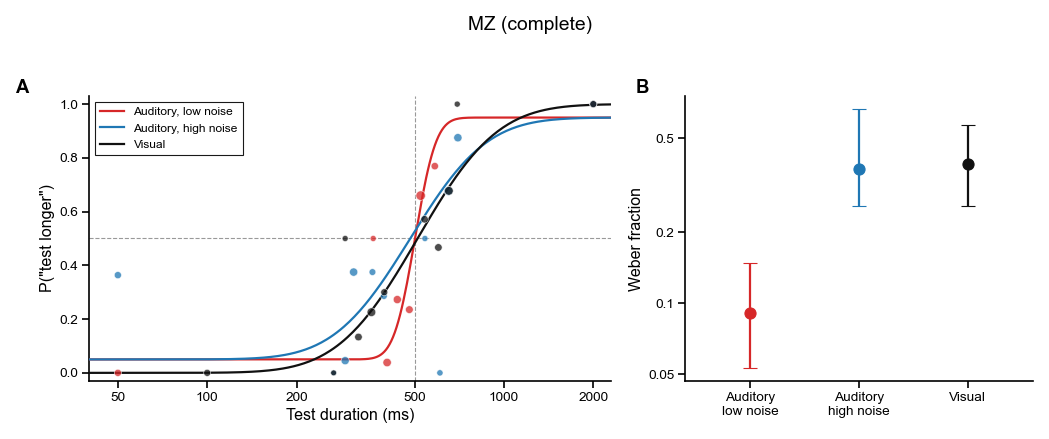

In [7]:
fig = R.fig1_unimodal(WHO, measure=MEASURE, errorbar=ERRORBAR, complete_only=COMPLETE_ONLY)
plt.show()

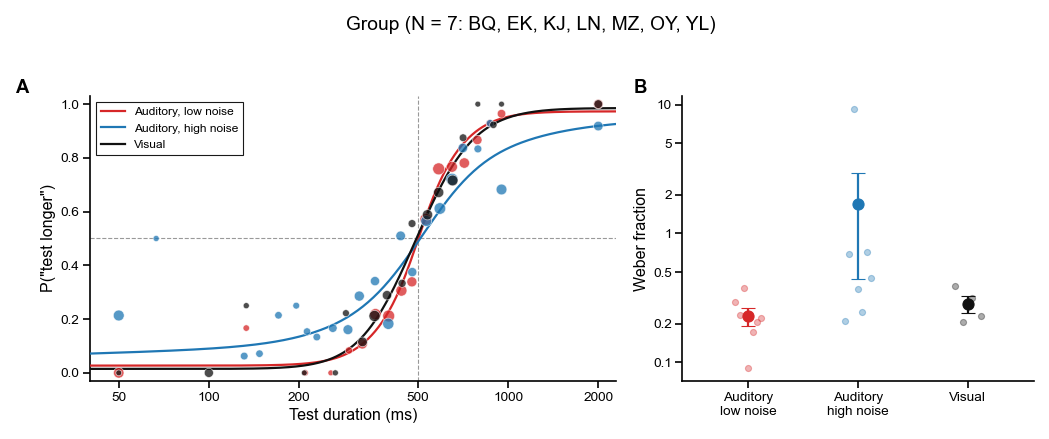

In [8]:
fig = R.fig1_unimodal("group", measure=MEASURE, errorbar=ERRORBAR, complete_only=COMPLETE_ONLY)
plt.show()

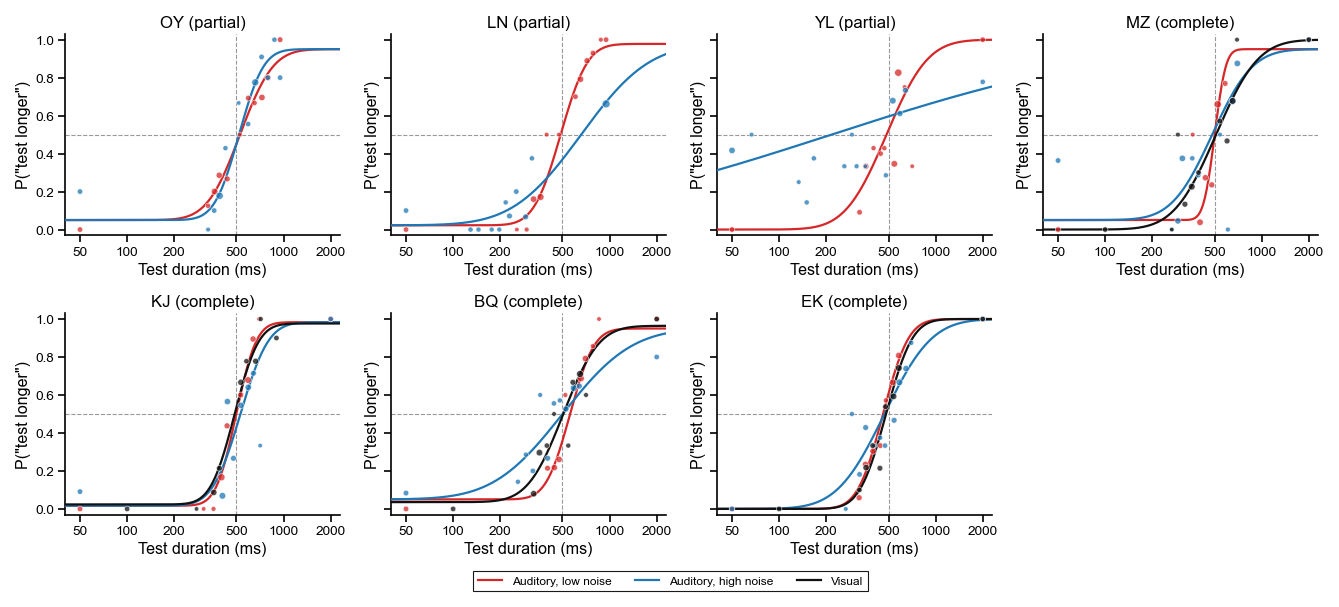

In [9]:
fig = R.fig1_unimodal("all", complete_only=COMPLETE_ONLY)
plt.show()

## Figure 2: bimodal psychometric curves across conflicts
A: low auditory noise, B: high auditory noise; lighter = more negative conflict (visual standard shorter).

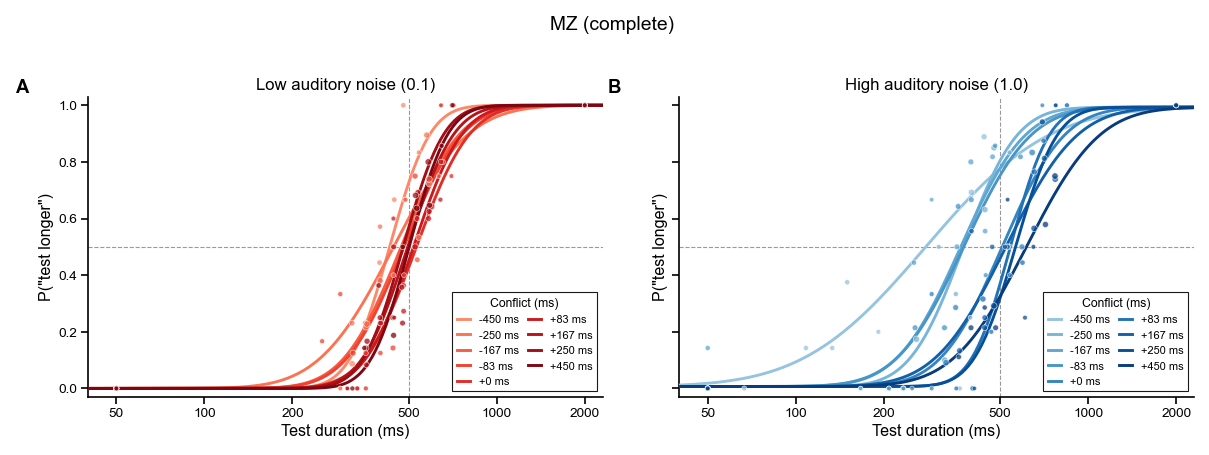

In [10]:
fig = R.fig2_bimodal(WHO, complete_only=COMPLETE_ONLY)
plt.show()

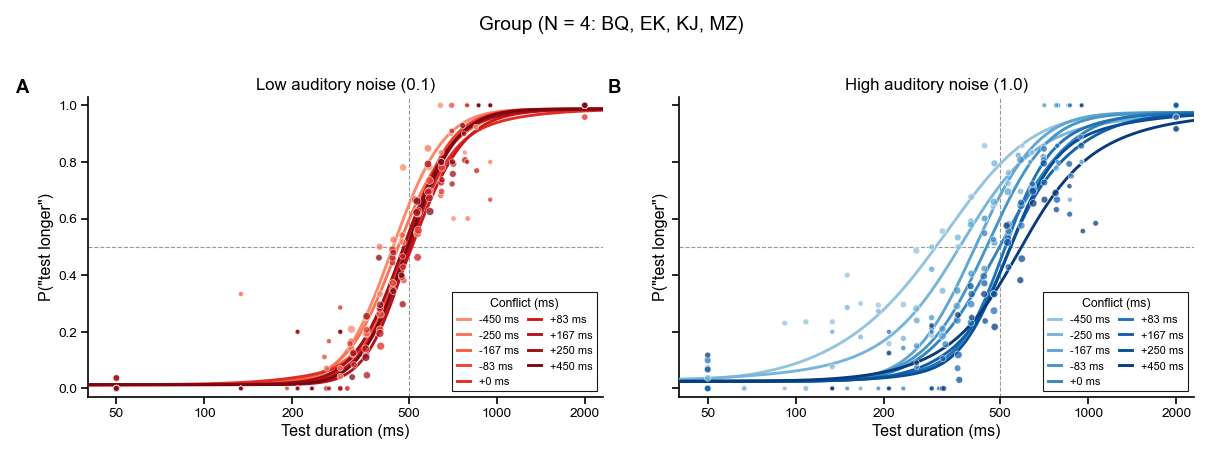

In [11]:
fig = R.fig2_bimodal("group", complete_only=COMPLETE_ONLY)
plt.show()

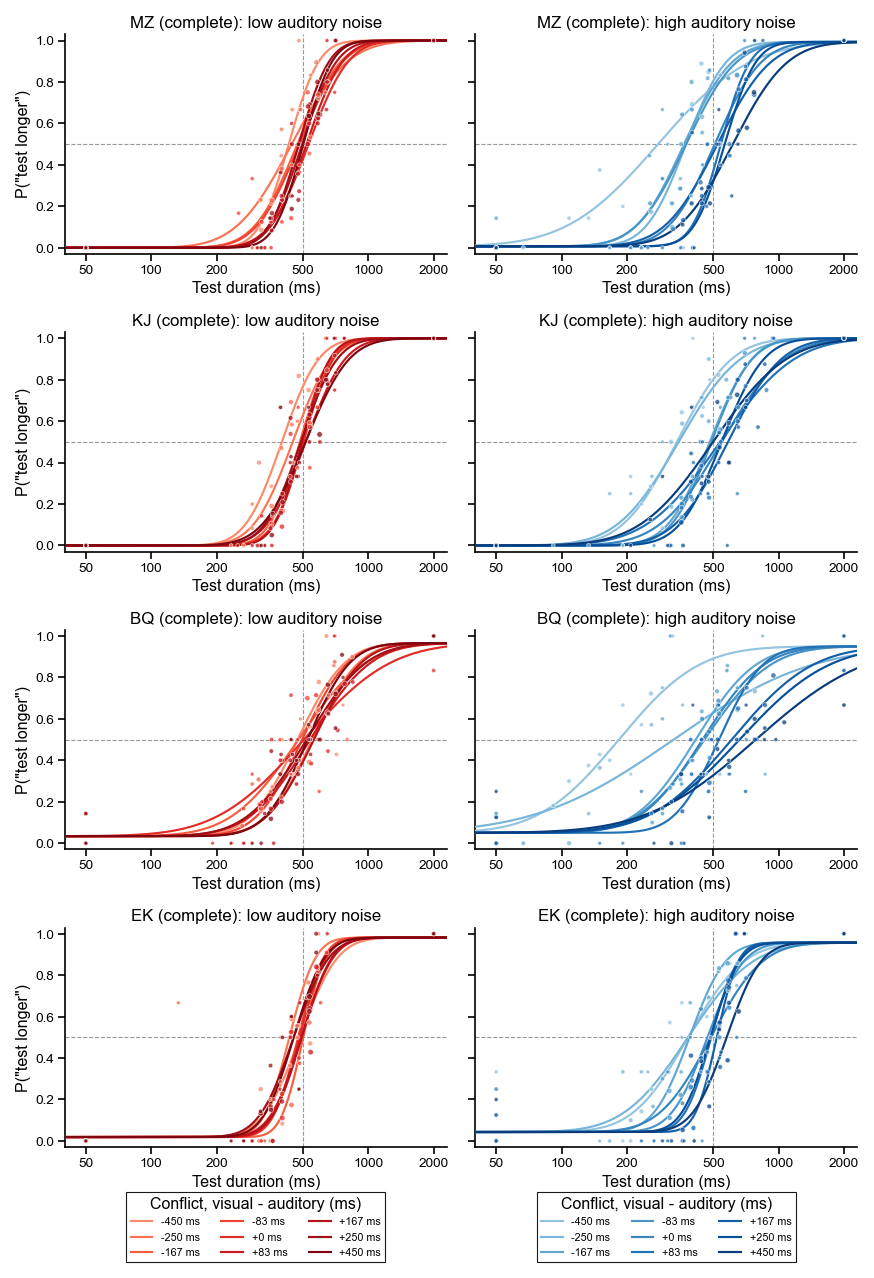

In [12]:
fig = R.fig2_bimodal("all", complete_only=COMPLETE_ONLY)
plt.show()

## Figure 3: effect of the audiovisual conflict on perceived auditory duration
A: PSE shift, B: σ, against conflict; red low noise, blue high noise (v1 colours). Dotted lines: the unimodal σ
(auditory per noise level, visual black).

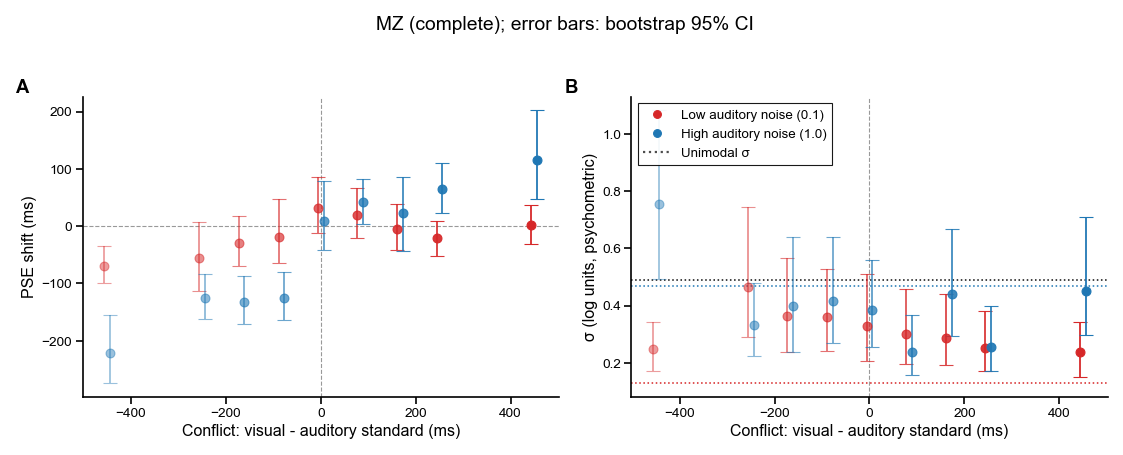

In [13]:
fig = R.fig3_conflict_effect(WHO, errorbar=ERRORBAR, baseline=BASELINE, sigma=SIGMA, complete_only=COMPLETE_ONLY)
plt.show()

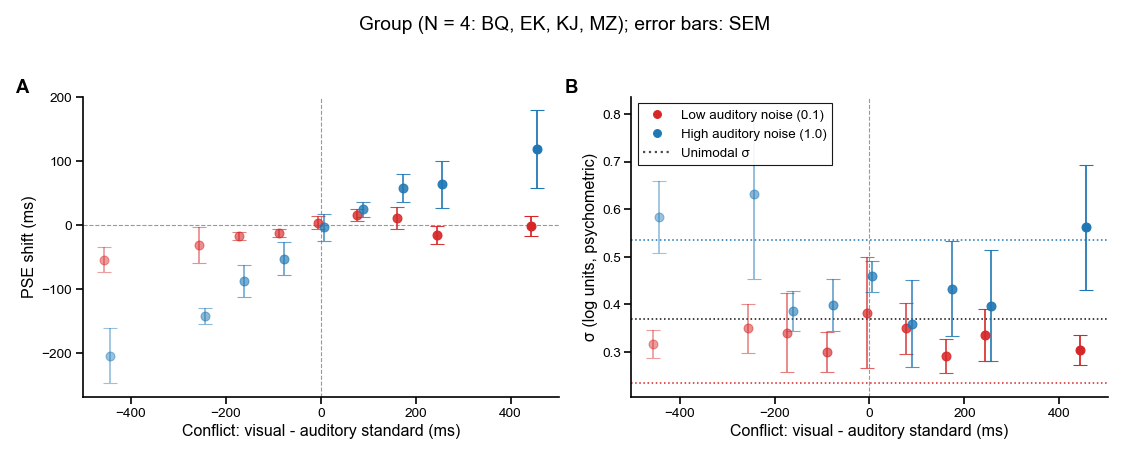

In [14]:
fig = R.fig3_conflict_effect("group", errorbar=ERRORBAR, baseline=BASELINE, sigma=SIGMA, complete_only=COMPLETE_ONLY)
plt.show()

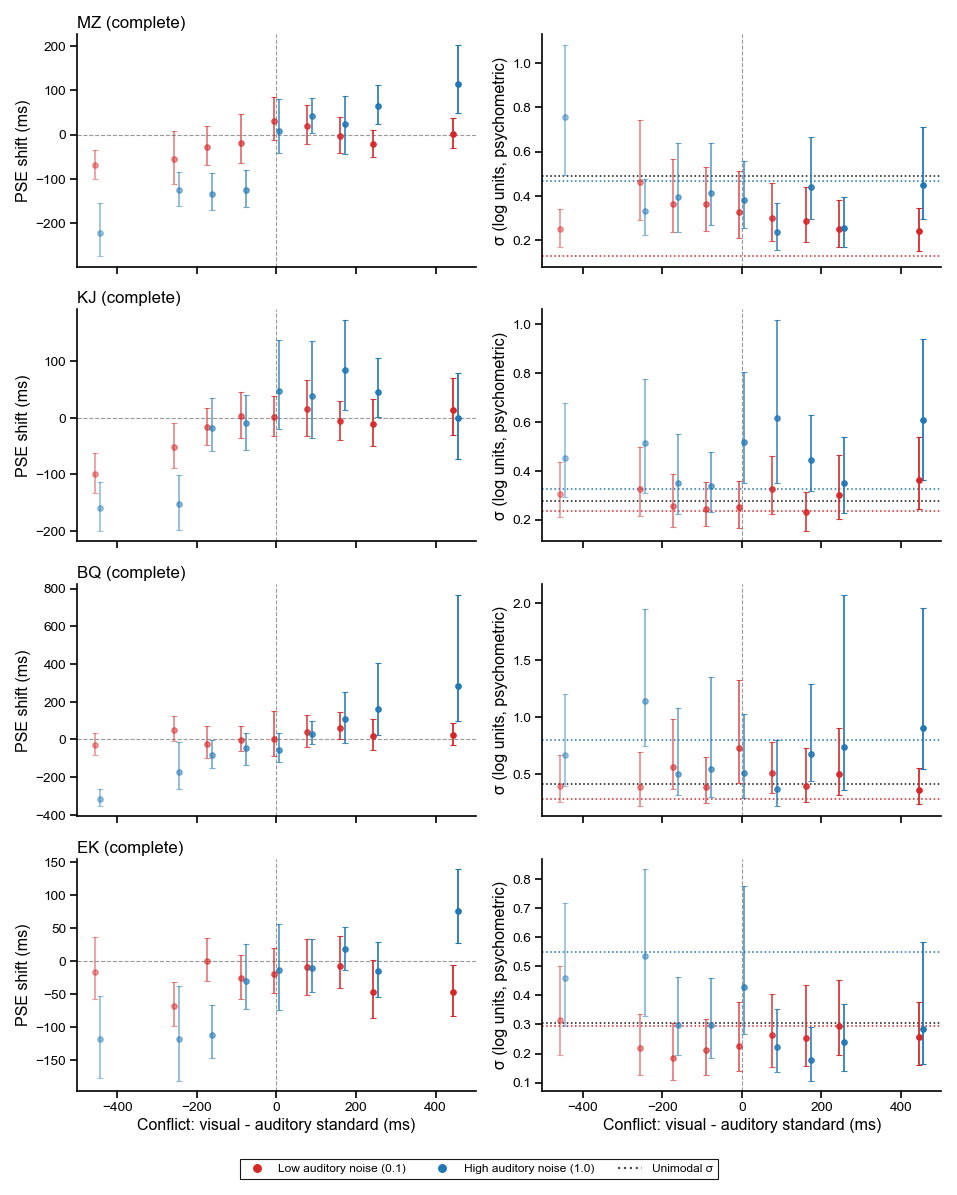

In [15]:
fig = R.fig3_conflict_effect("all", baseline=BASELINE, sigma=SIGMA, complete_only=COMPLETE_ONLY)
plt.show()

Against each participant's own 0-conflict PSE (a reviewer's suggestion on v1); the interval of the difference
comes from the same bootstrap samples.

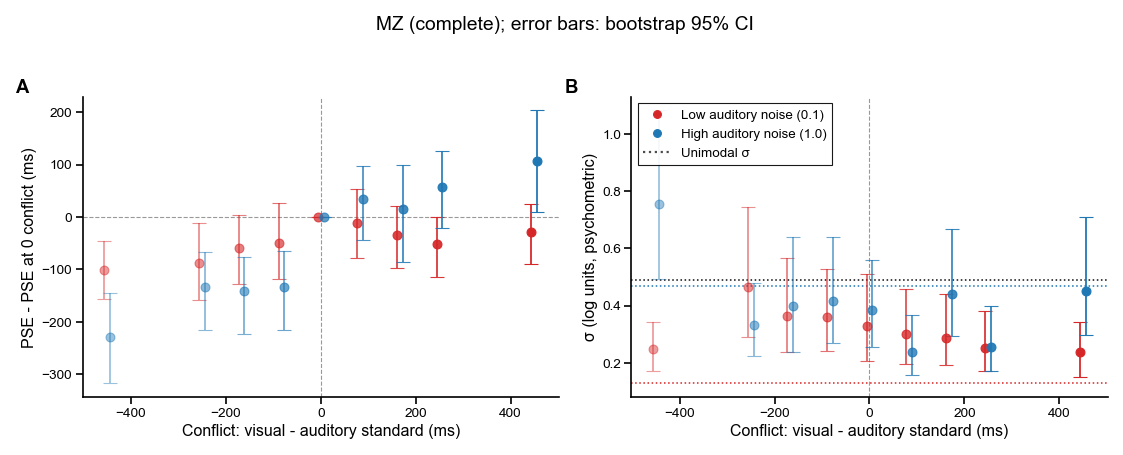

In [16]:
fig = R.fig3_conflict_effect(WHO, baseline="matched", sigma=SIGMA)
plt.show()

## Figure 4: staircases
Every staircase trial in order. Filled: answered "test longer", open: "standard longer", ×: reversal.
Grey lines separate the main parts.

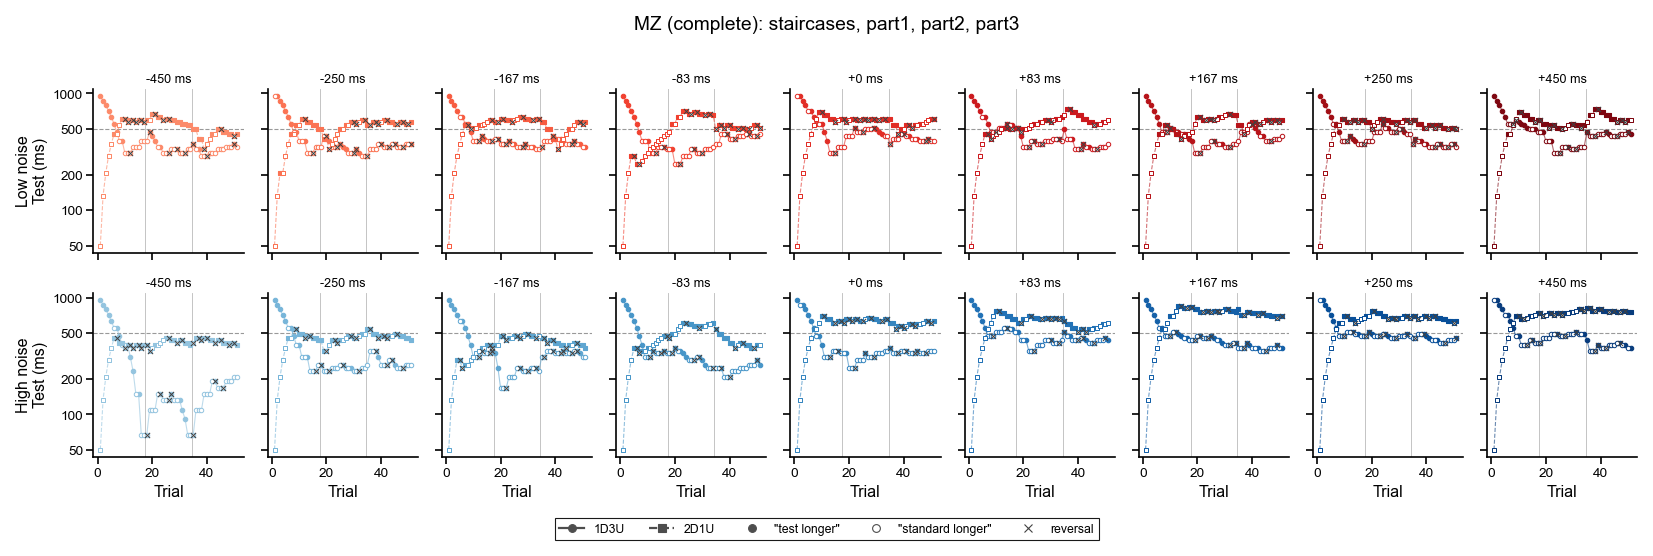

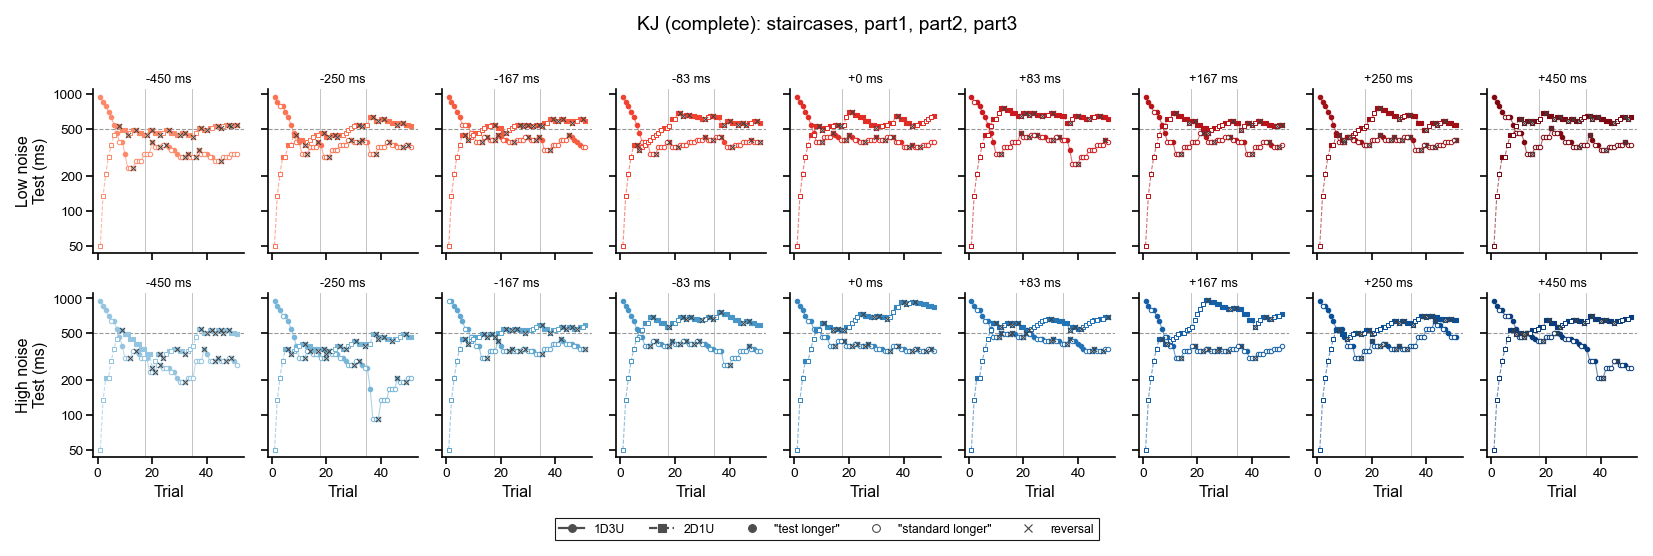

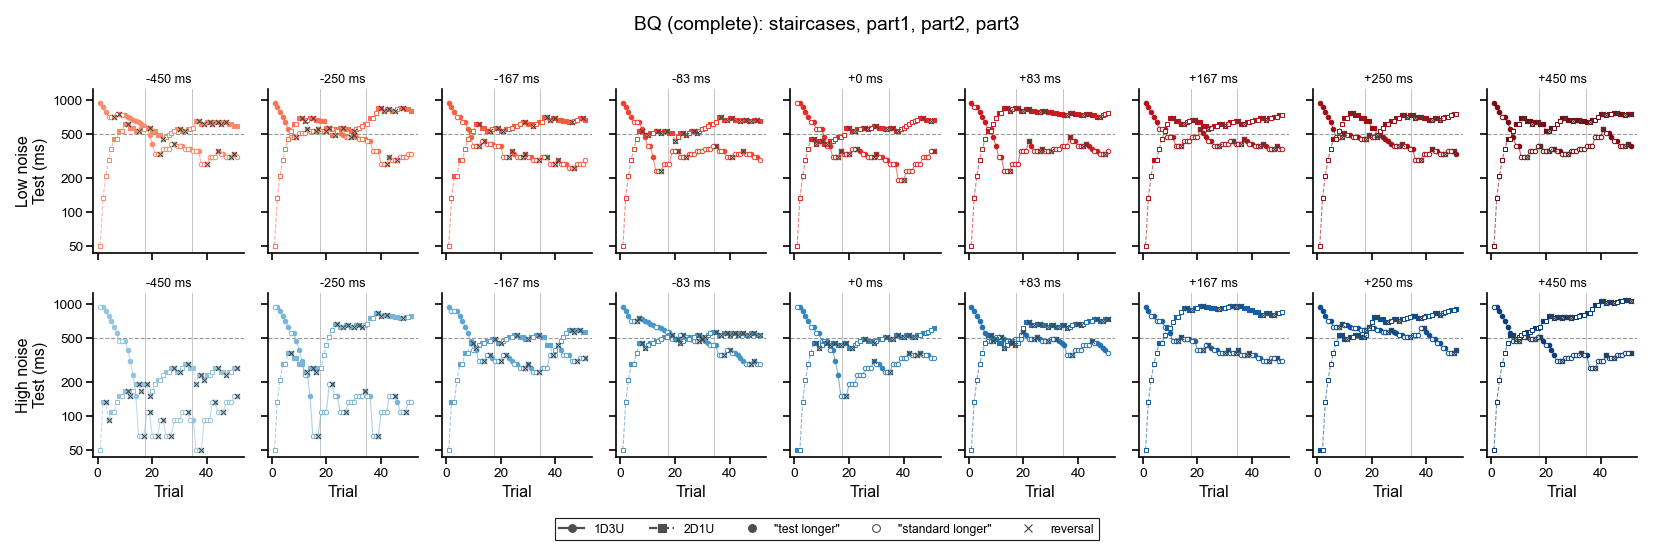

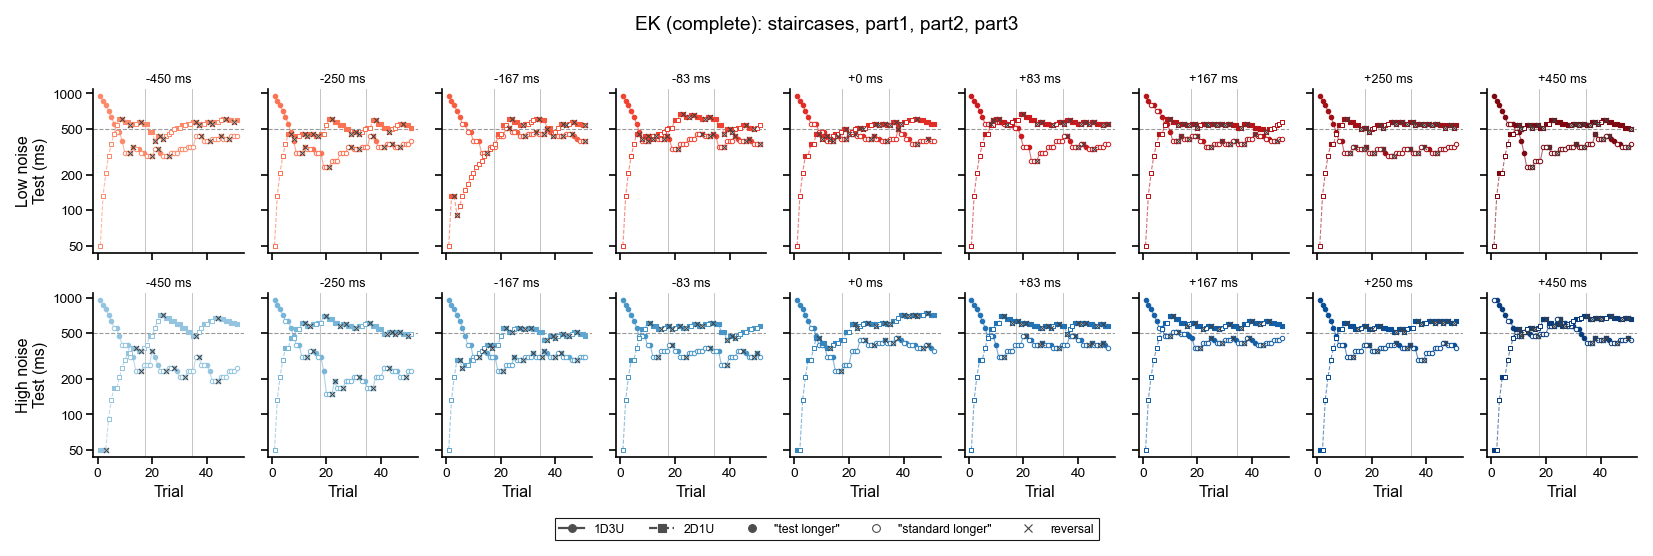

In [17]:
for pid in D.participants():
    s = D.status(pid)
    if s["main_parts"]:
        fig = R.fig4_staircases(pid, "main")
        plt.show()

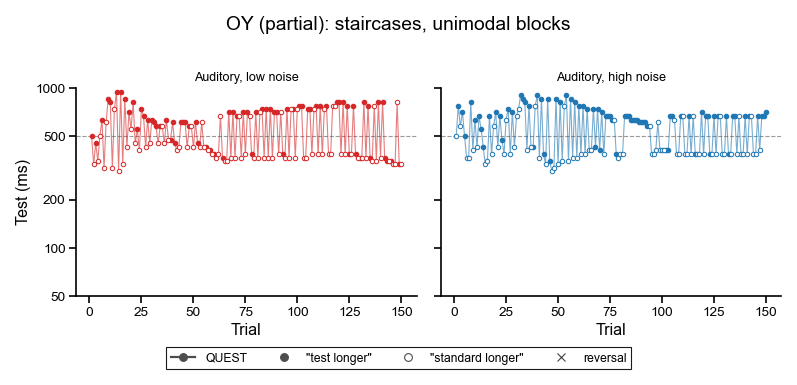

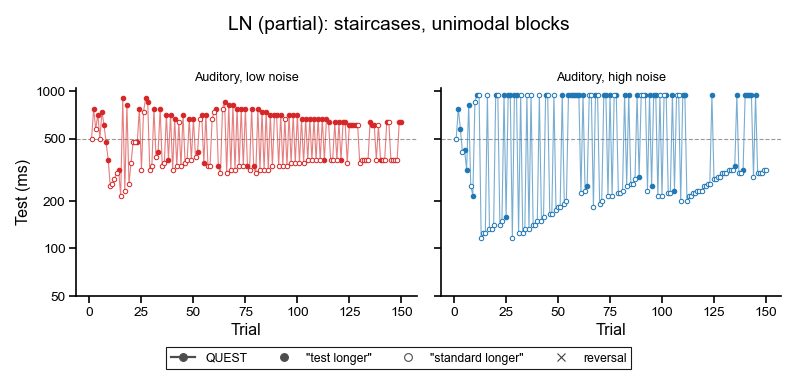

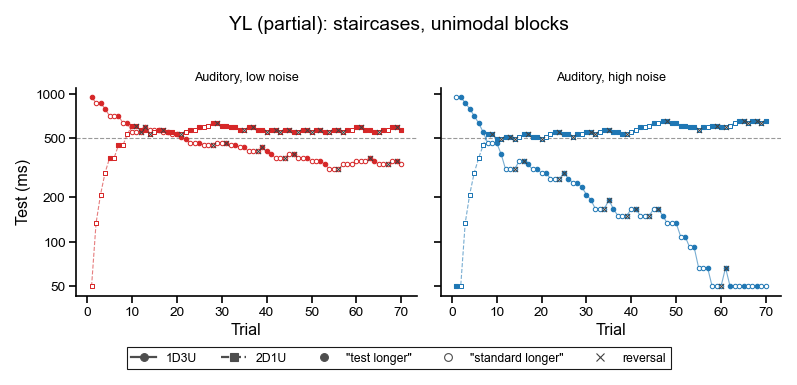

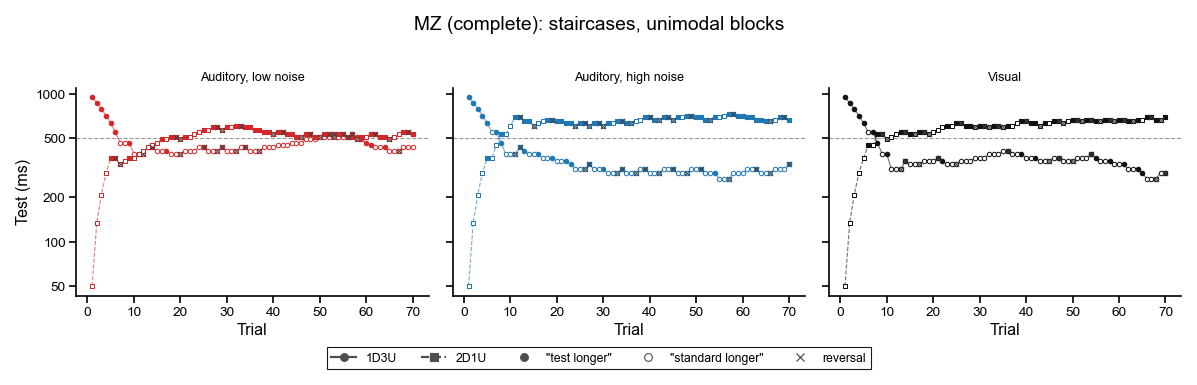

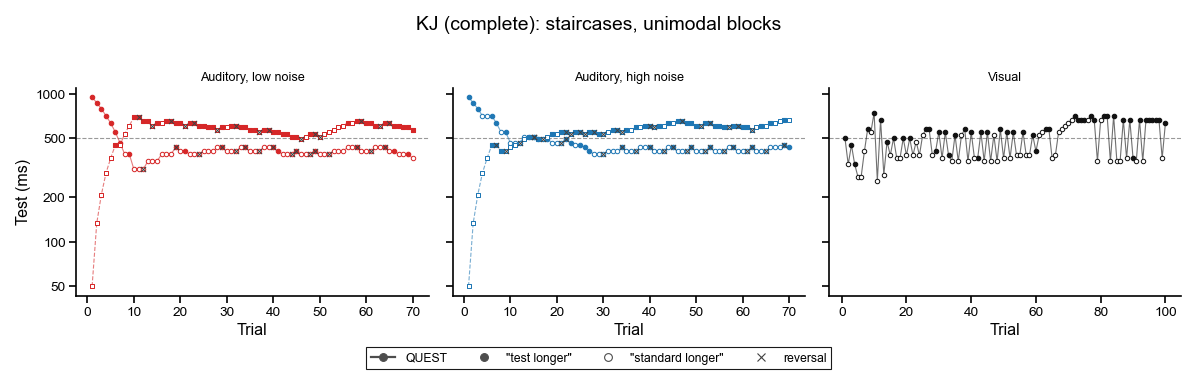

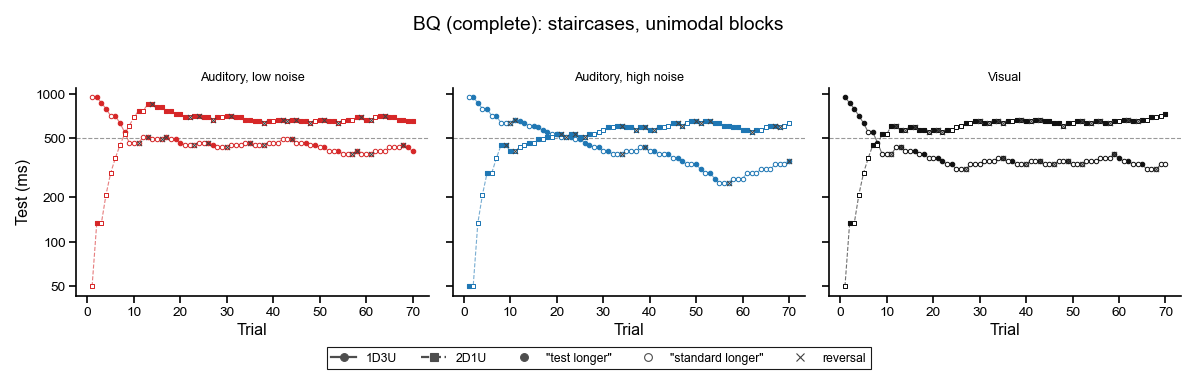

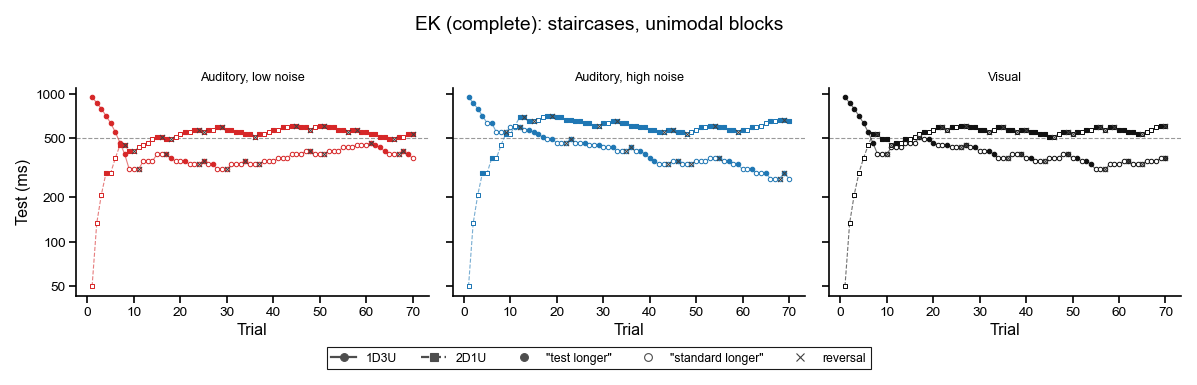

In [18]:
for pid in D.participants():
    fig = R.fig4_staircases(pid, "unimodal")
    plt.show()